In [3]:
%pip install pandas numpy matplotlib seaborn scikit-learn

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay,classification_report
from sklearn.tree import plot_tree

In [19]:

df = pd.read_csv("Telco-Customer-Churn.csv")

print("Original Dataset:")
print(df.head())

# 2. Clean dataset
df.drop(columns=["customerID"], inplace=True)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df.dropna(inplace=True)
df.drop_duplicates(inplace=True)

Original Dataset:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies   

In [10]:

# 3. Convert categorical data into numbers
for col in df.select_dtypes(include=["object", "str"]).columns:
    df[col] = df[col].str.strip()

# 4. Separate features and target
X = df.drop("Churn", axis=1)
y = df["Churn"]


Model Accuracy: 78.82 %

Classification Report:
              precision    recall  f1-score   support

    No Churn      0.824     0.905     0.863      1031
       Churn      0.637     0.464     0.537       371

    accuracy                          0.788      1402
   macro avg      0.731     0.684     0.700      1402
weighted avg      0.775     0.788     0.776      1402



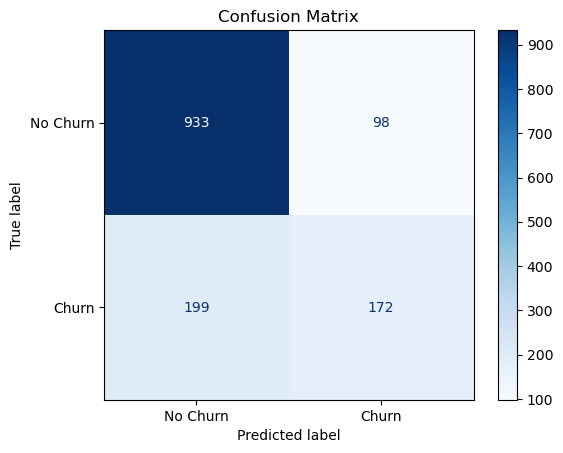

In [20]:
# 5. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 6. Train Random Forest model
model = RandomForestClassifier(
    n_estimators=100, random_state=42
)
model.fit(X_train, y_train)

# 7. Test model
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"],
    digits=3
))

# 8. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
).plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix")
plt.show()

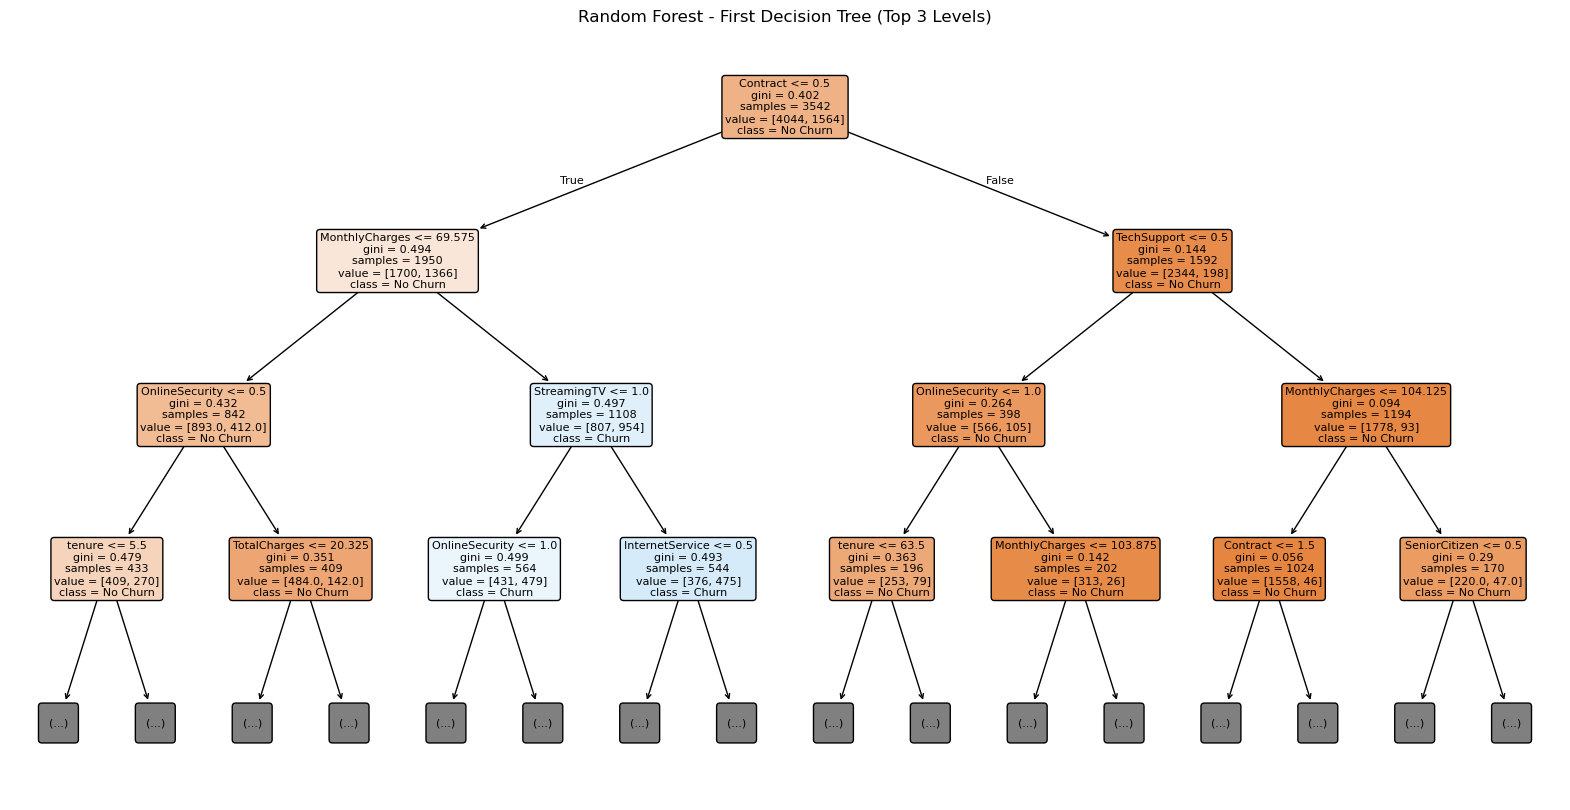

In [17]:
plt.figure(figsize=(20, 10))
plot_tree(
    model.estimators_[0],
    feature_names=X.columns,
    class_names=["No Churn", "Churn"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title("Random Forest - First Decision Tree (Top 3 Levels)")
plt.show()
